# Experiments
Notebook per confrontare run con iperparametri diversi.
Il dataset viene costruito e splittato **una volta sola** e condiviso tra tutti gli esperimenti per un confronto equo.
I log vengono salvati in `experiment_logs/<nome>/` come CSV di PyTorch Lightning.

In [1]:
import sys, os
sys.path.insert(0, 'src')

import torch
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import pytorch_lightning as pl
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping

from src.complex_dataset import ComplexDataset, complex_collate_fn, build_complex_dataset
from src.baseline import BaselineGNN

from src.graphmatchingnetwork import GraphMatchingNetwork

PROCESSED_DIR = 'data/processed'
CSV_PATH      = 'data/raw/PL_cleaned_index.csv'
LOGS_DIR      = 'experiment_logs'
SEED          = 47

torch.manual_seed(SEED)

## Dataset — costruito una volta sola

In [2]:
full_dataset = build_complex_dataset(PROCESSED_DIR, CSV_PATH, limit=1000)
train_codes, val_codes = train_test_split(full_dataset.pdb_codes, test_size=0.2, random_state=SEED)

print(f'Train: {len(train_codes)} complessi | Val: {len(val_codes)} complessi')

Train: 269 complessi | Val: 68 complessi


## Configurazioni esperimenti
Aggiungi o modifica entry nella lista `EXPERIMENTS`. Ogni dict deve avere il campo `name` (usato come nome della cartella log).

In [ ]:
# ESPERIMENTO 1 stessi iperparametri, nessuna regolarizzazione, baseline vs gmn
EXPERIMENTS = [
    {
        'name':               'baseline_no_reg',
        'model':              'baseline',
        'token_dim':          16,
        'node_embedding_dim': 48,
        'edge_embedding_dim': 32,
        'lr':                 5e-4,
        'dropout_p':          0.0,
        'normalization':      False,
        'batch_size':         16,
        'epochs':             50,
    },
    {
        'name':               'gmn_no_reg',
        'model':              'gmn',
        'token_dim':          16,
        'node_embedding_dim': 48,
        'edge_embedding_dim': 32,
        'num_layers':         3,
        'lr':                 5e-4,
        'dropout_p':          0.0,
        'normalization':      False,
        'batch_size':         16,
        'epochs':             50,
    },
]
"""
EXPERIMENTS = [
    
    {
        'name':               'baseline_no_reg',
        'model':              'baseline',
        'token_dim':          16,
        'node_embedding_dim': 48,
        'edge_embedding_dim': 32,
        'lr':                 5e-4,
        'dropout_p':          0.0,
        'normalization':      False,
        'batch_size':         16,
        'epochs':             50,
    },
    {
        'name':               'baseline_norm_dropout',
        'model':              'baseline',
        'token_dim':          16,
        'node_embedding_dim': 48,
        'edge_embedding_dim': 32,
        'lr':                 5e-4,
        'dropout_p':          0.2,
        'normalization':      True,
        'batch_size':         16,
        'epochs':             50,
    },
    {
        'name':               'baseline_large',
        'model':              'baseline',
        'token_dim':          32,
        'node_embedding_dim': 128,
        'edge_embedding_dim': 64,
        'lr':                 1e-3,
        'dropout_p':          0.1,
        'normalization':      True,
        'batch_size':         16,
        'epochs':             50,
    },
    
    {
        'name':               'gmn_no_reg',
        'model':              'gmn',
        'token_dim':          16,
        'node_embedding_dim': 48,
        'edge_embedding_dim': 32,
        'num_layers':         3,
        'lr':                 5e-4,
        'dropout_p':          0.0,
        'normalization':      False,
        'batch_size':         16,
        'epochs':             50,
    },
    {
        'name':               'gmn_norm_dropout',
        'model':              'gmn',
        'token_dim':          16,
        'node_embedding_dim': 48,
        'edge_embedding_dim': 32,
        'num_layers':         3,
        'lr':                 5e-4,
        'dropout_p':          0.1,
        'normalization':      True,
        'batch_size':         16,
        'epochs':             50,
    },
]
"""

## Funzione di training

In [5]:
def run_experiment(cfg, train_codes, val_codes):
    train_ds = ComplexDataset(PROCESSED_DIR, train_codes)
    val_ds   = ComplexDataset(PROCESSED_DIR, val_codes)

    train_loader = DataLoader(
        train_ds, batch_size=cfg['batch_size'], shuffle=True,
        collate_fn=complex_collate_fn, num_workers=4,
    )
    val_loader = DataLoader(
        val_ds, batch_size=cfg['batch_size'], shuffle=False,
        collate_fn=complex_collate_fn, num_workers=0,
    )

    if cfg['model'] == 'gmn':
        model = GraphMatchingNetwork(
            token_dim=cfg['token_dim'],
            node_embedding_dim=cfg['node_embedding_dim'],
            edge_embedding_dim=cfg['edge_embedding_dim'],
            num_layers=cfg.get('num_layers', 3),
            lr=cfg['lr'],
            dropout_p=cfg['dropout_p'],
            normalization=cfg['normalization'],
        )
    else:
        model = BaselineGNN(
            token_dim=cfg['token_dim'],
            node_embedding_dim=cfg['node_embedding_dim'],
            edge_embedding_dim=cfg['edge_embedding_dim'],
            lr=cfg['lr'],
            dropout_p=cfg['dropout_p'],
            normalization=cfg['normalization'],
        )

    logger = CSVLogger(LOGS_DIR, name=cfg['name'])

    callbacks = [
        ModelCheckpoint(
            dirpath=logger.log_dir,
            filename='best',
            monitor='val_loss',
            mode='min',
            save_top_k=1,
        ),
        EarlyStopping(monitor='val_loss', patience=10, mode='min'),
    ]

    trainer = pl.Trainer(
        max_epochs=cfg['epochs'],
        precision='16-mixed',
        log_every_n_steps=10,
        logger=logger,
        callbacks=callbacks,
        enable_progress_bar=True,
    )

    trainer.fit(model, train_loader, val_loader)

    metrics = pd.read_csv(os.path.join(logger.log_dir, 'metrics.csv'))
    best_val = metrics['val_loss'].dropna().min()
    print(f"[{cfg['name']}]  best val_loss = {best_val:.4f}")
    return metrics

## Run

In [6]:
results = {}
for cfg in EXPERIMENTS:
    print(f"\n{'='*55}\n  {cfg['name']}\n{'='*55}")
    results[cfg['name']] = run_experiment(cfg, train_codes, val_codes)


  baseline_no_reg


c:\Users\isare\AppData\Local\Programs\Python\Python311\Lib\site-packages\pytorch_lightning\trainer\connectors\accelerator_connector.py:479: You passed `Trainer(accelerator='cpu', precision='16-mixed')` but AMP with fp16 is not supported on CPU. Using `precision='bf16-mixed'` instead.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
c:\Users\isare\AppData\Local\Programs\Python\Python311\Lib\site-packages\pytorch_lightning\utilities\model_summary\model_summary.py:242: Precision bf16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type                 ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ tokenizer │ DualFeatureTokenizer │ 24.8 K │ train │     0 │
│ 1 │ prot_gnn  │ GINEConv             │  6.3 K │ train │     0 │
│ 2 │ lig_gnn   │ GINEConv             │  6.3 K │ train │     0 │
│ 3 │ mlp       │ Sequential           │  4.7 K │ train │     0 │
└───┴───────────┴──────────────────────┴────────┴───────┴───────┘

Trainable params: 42.1 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 42.1 K                                                                                               
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 65                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

...

c:\Users\isare\AppData\Local\Programs\Python\Python311\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.

c:\Users\isare\AppData\Local\Programs\Python\Python311\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:429: Consider setting `persistent_workers=True` in 'train_dataloader' to speed up the dataloader 
worker initialization.


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

C:\Users\isare\AppData\Roaming\Python\Python311\site-packages\IPython\core\interactiveshell.py:3709: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## Risultati

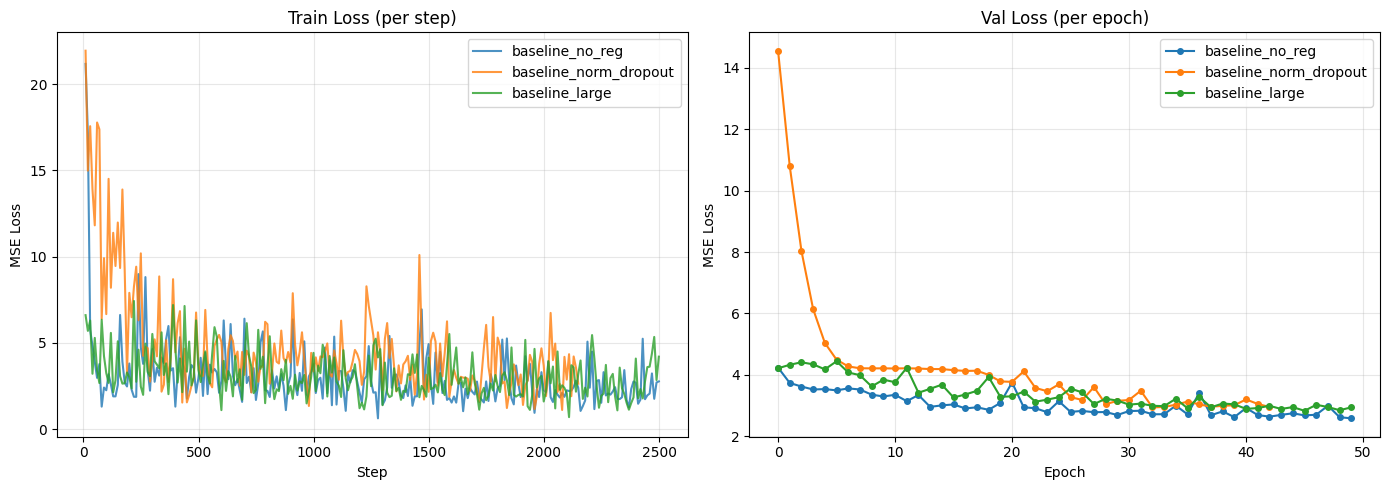

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#on the graph: baseline: solid line, GMN: dashed line
styles = {
    'baseline': {'linestyle': '-'},
    'gmn':      {'linestyle': '--'},
}

for cfg in EXPERIMENTS:
    name = cfg['name']
    if name not in results:
        continue
    metrics = results[name]
    s = styles[cfg['model']]

    train_m = metrics[metrics['train_loss'].notna()]
    val_m   = metrics[metrics['val_loss'].notna()]

    axes[0].plot(train_m['step'], train_m['train_loss'],
                 label=name, alpha=0.8, **s)
    axes[1].plot(val_m['epoch'], val_m['val_loss'],
                 label=name, marker='o', markersize=4, **s)

for ax, title, xlabel in zip(
    axes,
    ['Train Loss (per step)', 'Val Loss (per epoch)'],
    ['Step', 'Epoch'],
):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('MSE Loss')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
os.makedirs(LOGS_DIR, exist_ok=True)
plt.savefig(os.path.join(LOGS_DIR, 'comparison.png'), dpi=150)
plt.show()

In [ ]:
summary = []
for cfg in EXPERIMENTS:
    name = cfg['name']
    if name not in results:
        continue
    best_val = results[name]['val_loss'].dropna().min()
    stopped_at = int(results[name]['epoch'].max())
    summary.append({
        'name':               name,
        'model':              cfg['model'],
        'best_val_loss':      round(float(best_val), 4),
        'stopped_epoch':      stopped_at,
        'node_embedding_dim': cfg['node_embedding_dim'],
        'num_layers':         cfg.get('num_layers', 1),
        'normalization':      cfg['normalization'],
        'dropout_p':          cfg['dropout_p'],
        'lr':                 cfg['lr'],
    })

pd.DataFrame(summary).set_index('name').sort_values('best_val_loss')

,best_val_loss,stopped_epoch,node_embedding_dim,normalization,dropout_p,lr
name,,,,,,
baseline_no_reg,2.5844,49,48,False,0.0,0.0005
baseline_large,2.8294,49,128,True,0.1,0.0010
baseline_norm_dropout,2.9395,42,48,True,0.2,0.0005
